# RQ1 Step 6: Weighted KNN trajectory regression

This notebook implements a nonparametric analogue method. For each query case, it finds training cases with the most similar 24-hour history and predicts the complete future trajectory by a distance-weighted average of their observed 72-hour futures.


## 1. Model definition

The prediction averages the 144-dimensional future targets of the nearest $K$ training cases, with weights proportional to inverse distance raised to power $p$. Grouped training cross-validation selects both $K$ and $p$.


In [1]:
from pathlib import Path
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython import get_ipython
from IPython.display import display

ipython = get_ipython()
if ipython is not None:
    ipython.run_line_magic('matplotlib', 'inline')

PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data' / 'processed').exists()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Could not find data/processed; open the notebook from the project directory or a notebook subdirectory.')

PROCESSED = PROJECT_ROOT / 'data' / 'processed'
OUTPUT_DIR = PROJECT_ROOT / 'output' / 'rq1' / 'en'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EARTH_RADIUS_KM = 6_371.0
HISTORY_HOURS = 24
HORIZON_HOURS = 72
N_FOLDS = 5
K_VALUES = [5, 10, 20, 50, 100]
DISTANCE_POWERS = [1.0, 2.0]
MAX_K = max(K_VALUES)
QUERY_BATCH_SIZE = 256

plt.rcParams['font.sans-serif'] = ['PingFang SC', 'Arial Unicode MS', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
print('Project directory: ', PROJECT_ROOT.resolve())
print('Output directory: ', OUTPUT_DIR.resolve())

Project directory:  /Users/roger/Documents/data3001-project-main
Output directory:  /Users/roger/Documents/data3001-project-main/output/rq1/en


## 2. Convert spherical positions and local displacements

Inputs and targets use displacement relative to the forecast origin, while final evaluation is performed in latitude/longitude with Haversine distance.


In [2]:
def latlon_to_local_km(origin_lat, origin_lon, latitude, longitude):
    lat0 = np.deg2rad(np.asarray(origin_lat, dtype=float))
    lon0 = np.deg2rad(np.asarray(origin_lon, dtype=float))
    lat1 = np.deg2rad(np.asarray(latitude, dtype=float))
    lon1 = np.deg2rad(np.asarray(longitude, dtype=float))
    dlon = (lon1 - lon0 + np.pi) % (2 * np.pi) - np.pi
    dlat = lat1 - lat0
    a = np.sin(dlat / 2) ** 2 + np.cos(lat0) * np.cos(lat1) * np.sin(dlon / 2) ** 2
    central_angle = 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
    bearing = np.arctan2(
        np.sin(dlon) * np.cos(lat1),
        np.cos(lat0) * np.sin(lat1) - np.sin(lat0) * np.cos(lat1) * np.cos(dlon),
    )
    distance_km = EARTH_RADIUS_KM * central_angle
    return distance_km * np.sin(bearing), distance_km * np.cos(bearing)


def local_km_to_latlon(origin_lat, origin_lon, east_km, north_km):
    lat0 = np.deg2rad(np.asarray(origin_lat, dtype=float))
    lon0 = np.deg2rad(np.asarray(origin_lon, dtype=float))
    east_km = np.asarray(east_km, dtype=float)
    north_km = np.asarray(north_km, dtype=float)
    distance_km = np.hypot(east_km, north_km)
    bearing = np.arctan2(east_km, north_km)
    angular_distance = distance_km / EARTH_RADIUS_KM
    latitude = np.arcsin(
        np.sin(lat0) * np.cos(angular_distance)
        + np.cos(lat0) * np.sin(angular_distance) * np.cos(bearing)
    )
    longitude = lon0 + np.arctan2(
        np.sin(bearing) * np.sin(angular_distance) * np.cos(lat0),
        np.cos(angular_distance) - np.sin(lat0) * np.sin(latitude),
    )
    return np.rad2deg(latitude), (np.rad2deg(longitude) + 180.0) % 360.0 - 180.0


def haversine_km(lat1, lon1, lat2, lon2):
    lat1 = np.deg2rad(np.asarray(lat1, dtype=float))
    lon1 = np.deg2rad(np.asarray(lon1, dtype=float))
    lat2 = np.deg2rad(np.asarray(lat2, dtype=float))
    lon2 = np.deg2rad(np.asarray(lon2, dtype=float))
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 2 * EARTH_RADIUS_KM * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

## 3. Construct the same 98 inputs as Ridge and FNN

Each case contains origin latitude/longitude plus 24 hourly relative positions and velocities. Reusing identical features isolates the effect of the forecasting algorithm.


In [3]:
origins = (
    pd.read_parquet(PROCESSED / 'forecast_origins.parquet')
    .sort_values('forecast_case_id').reset_index(drop=True)
)
observations = pd.read_parquet(
    PROCESSED / 'region_A_observations.parquet',
    columns=['ID', 'segment_id', 'segment_step', 'time', 'latitude', 'longitude', 've', 'vn'],
)
n_cases = len(origins)

history = origins[[
    'forecast_case_id', 'ID', 'segment_id', 'history_start_step',
    'origin_latitude', 'origin_longitude',
]].loc[origins.index.repeat(HISTORY_HOURS)].reset_index(drop=True)
history['history_index'] = np.tile(np.arange(HISTORY_HOURS), n_cases)
history['segment_step'] = history['history_start_step'] + history['history_index']
history = history.merge(
    observations, on=['ID', 'segment_id', 'segment_step'],
    how='left', validate='many_to_one',
).sort_values(['forecast_case_id', 'history_index']).reset_index(drop=True)

history['relative_east_km'], history['relative_north_km'] = latlon_to_local_km(
    history['origin_latitude'], history['origin_longitude'],
    history['latitude'], history['longitude'],
)
history_values = history[[
    'relative_east_km', 'relative_north_km', 've', 'vn',
]].to_numpy().reshape(n_cases, HISTORY_HOURS, 4)
X = np.column_stack([
    origins['origin_latitude'].to_numpy(),
    origins['origin_longitude'].to_numpy(),
    history_values.reshape(n_cases, -1),
]).astype(np.float64)

history_checks = pd.Series({
    'There are 5,117 cases': n_cases == 5117,
    'Every case has exactly 24 historical observations': history.groupby('forecast_case_id').size().eq(24).all(),
    'Input matrix has shape 5117 x 98': X.shape == (5117, 98),
    'Inputs contain no missing or infinite values': np.isfinite(X).all(),
}, name='Passed')
display(history_checks.to_frame())
assert history_checks.all()

,Passed
"There are 5,117 cases",True
Every case has exactly 24 historical observations,True
Input matrix has shape 5117 x 98,True
Inputs contain no missing or infinite values,True


## 4. Construct 144 future targets

The target is the complete 72-hour future trajectory represented as east/north displacement pairs.


In [4]:
targets = origins[[
    'forecast_case_id', 'ID', 'segment_id', 'target_start_step',
    'origin_latitude', 'origin_longitude',
]].loc[origins.index.repeat(HORIZON_HOURS)].reset_index(drop=True)
targets['lead_time_hours'] = np.tile(np.arange(1, HORIZON_HOURS + 1), n_cases)
targets['segment_step'] = targets['target_start_step'] + targets['lead_time_hours'] - 1
targets = targets.merge(
    observations[['ID', 'segment_id', 'segment_step', 'time', 'latitude', 'longitude']],
    on=['ID', 'segment_id', 'segment_step'], how='left', validate='many_to_one',
).sort_values(['forecast_case_id', 'lead_time_hours']).reset_index(drop=True)

targets['target_east_km'], targets['target_north_km'] = latlon_to_local_km(
    targets['origin_latitude'], targets['origin_longitude'],
    targets['latitude'], targets['longitude'],
)
Y = targets[['target_east_km', 'target_north_km']].to_numpy().reshape(
    n_cases, HORIZON_HOURS * 2
).astype(np.float64)

target_checks = pd.Series({
    'Every case has exactly 72 future observations': targets.groupby('forecast_case_id').size().eq(72).all(),
    'Target matrix has shape 5117 x 144': Y.shape == (5117, 144),
    'Targets contain no missing or infinite values': np.isfinite(Y).all(),
}, name='Passed')
display(target_checks.to_frame())
assert target_checks.all()

,Passed
Every case has exactly 72 future observations,True
Target matrix has shape 5117 x 144,True
Targets contain no missing or infinite values,True


## 5. Build five grouped folds within training drifters

All cases from one drifter remain together so adjacent windows from the same physical track cannot become neighbours across training and validation.


In [5]:
train_indices = np.flatnonzero(origins['partition'].eq('training').to_numpy())
calibration_indices = np.flatnonzero(origins['partition'].eq('calibration').to_numpy())
test_indices = np.flatnonzero(origins['partition'].eq('test').to_numpy())

training_group_counts = origins.loc[train_indices].groupby('ID').size().sort_values(ascending=False)
fold_drifters = [[] for _ in range(N_FOLDS)]
fold_case_counts = np.zeros(N_FOLDS, dtype=int)
for drifter_id, count in training_group_counts.items():
    fold = int(np.argmin(fold_case_counts))
    fold_drifters[fold].append(drifter_id)
    fold_case_counts[fold] += int(count)

fold_summary = pd.DataFrame({
    'Fold': np.arange(1, N_FOLDS + 1),
    'Training drifters held out': [len(x) for x in fold_drifters],
    'Validation cases': fold_case_counts,
})
display(fold_summary)

assert len(train_indices) == 3591
assert len(calibration_indices) == 769
assert len(test_indices) == 757
assert fold_case_counts.sum() == len(train_indices)

,Fold,Training drifters held out,Validation cases
0,1,63,719
1,2,62,718
2,3,62,718
3,4,62,718
4,5,62,718


## 6. Nearest-neighbour search and weighted prediction

Features are standardised using the active training subset. Batched matrix calculations find the nearest neighbours in 98 dimensions and inverse-distance weights combine their future trajectories.


In [6]:
def standardise_from_training(X_train, X_query):
    mean = X_train.mean(axis=0)
    scale = X_train.std(axis=0)
    scale[scale < 1e-12] = 1.0
    return (X_train - mean) / scale, (X_query - mean) / scale, mean, scale


def find_nearest_neighbours(X_train_standard, X_query_standard, max_k=MAX_K):
    if max_k > len(X_train_standard):
        raise ValueError('max_k cannot exceed the number of training cases.')
    train_squared = np.sum(np.square(X_train_standard), axis=1)
    all_indices = []
    all_distances = []
    n_features = X_train_standard.shape[1]

    for start in range(0, len(X_query_standard), QUERY_BATCH_SIZE):
        query = X_query_standard[start:start + QUERY_BATCH_SIZE]
        query_squared = np.sum(np.square(query), axis=1, keepdims=True)
        squared_distances = (
            query_squared + train_squared[None, :] - 2.0 * query @ X_train_standard.T
        ) / n_features
        squared_distances = np.maximum(squared_distances, 0.0)
        candidate_indices = np.argpartition(
            squared_distances, kth=max_k - 1, axis=1
        )[:, :max_k]
        candidate_distances = np.take_along_axis(
            squared_distances, candidate_indices, axis=1
        )
        order = np.argsort(candidate_distances, axis=1)
        sorted_indices = np.take_along_axis(candidate_indices, order, axis=1)
        sorted_distances = np.sqrt(np.take_along_axis(candidate_distances, order, axis=1))
        all_indices.append(sorted_indices)
        all_distances.append(sorted_distances)

    return np.vstack(all_indices), np.vstack(all_distances)


def weighted_knn_predict(Y_train, neighbour_indices, neighbour_distances, k, power):
    indices = neighbour_indices[:, :k]
    distances = neighbour_distances[:, :k]
    weights = 1.0 / np.power(distances + 1e-8, power)
    weights /= weights.sum(axis=1, keepdims=True)
    neighbour_targets = Y_train[indices]
    prediction = np.einsum('nk,nko->no', weights, neighbour_targets, optimize=True)
    effective_neighbours = 1.0 / np.sum(np.square(weights), axis=1)
    return prediction, effective_neighbours

## 7. Select $K$ and distance weighting within training data

The candidate neighbour counts are 5, 10, 20, 50 and 100, with distance powers 1 and 2. Mean grouped validation displacement RMSE selects the final combination.


In [7]:
cv_rows = []
cv_start = time.time()

for fold_number, validation_drifters in enumerate(fold_drifters, start=1):
    is_validation = origins.loc[train_indices, 'ID'].isin(validation_drifters).to_numpy()
    fold_validation_indices = train_indices[is_validation]
    fold_training_indices = train_indices[~is_validation]

    X_train_standard, X_valid_standard, _, _ = standardise_from_training(
        X[fold_training_indices], X[fold_validation_indices]
    )
    neighbour_indices, neighbour_distances = find_nearest_neighbours(
        X_train_standard, X_valid_standard, max_k=MAX_K
    )

    # Grouped folds prevent the same drifter or adjacent windows from becoming neighbours.
    training_ids_in_fold = set(origins.loc[fold_training_indices, 'ID'])
    validation_ids_in_fold = set(origins.loc[fold_validation_indices, 'ID'])
    assert training_ids_in_fold.isdisjoint(validation_ids_in_fold)

    for power in DISTANCE_POWERS:
        for k in K_VALUES:
            prediction, effective_neighbours = weighted_knn_predict(
                Y[fold_training_indices], neighbour_indices, neighbour_distances, k, power
            )
            displacement_rmse = np.sqrt(np.mean(np.square(
                prediction - Y[fold_validation_indices]
            )))
            cv_rows.append({
                'fold': fold_number,
                'k': k,
                'distance_power': power,
                'training_cases': len(fold_training_indices),
                'validation_cases': len(fold_validation_indices),
                'mean_nearest_distance': neighbour_distances[:, 0].mean(),
                'median_effective_neighbours': np.median(effective_neighbours),
                'validation_displacement_rmse_km': displacement_rmse,
            })
    print(
        f'Fold {fold_number}: {len(fold_validation_indices)} validation cases，'
        f'mean nearest-neighbour distance={neighbour_distances[:, 0].mean():.3f}'
    )

cv_folds = pd.DataFrame(cv_rows)
cv_results = (
    cv_folds.groupby(['k', 'distance_power'])
    .agg(
        mean_cv_rmse_km=('validation_displacement_rmse_km', 'mean'),
        std_cv_rmse_km=('validation_displacement_rmse_km', 'std'),
        mean_nearest_distance=('mean_nearest_distance', 'mean'),
        median_effective_neighbours=('median_effective_neighbours', 'median'),
    )
    .reset_index()
)
best_row = cv_results.loc[cv_results['mean_cv_rmse_km'].idxmin()]
best_k = int(best_row['k'])
best_power = float(best_row['distance_power'])

display(cv_results.sort_values('mean_cv_rmse_km').round(3))
print(f'Selected: K={best_k}, distance power={best_power:g}')
print(f'Cross-validation time: {time.time() - cv_start:.1f} seconds')

Fold 1: 719 validation cases，mean nearest-neighbour distance=0.324
Fold 2: 718 validation cases，mean nearest-neighbour distance=0.323


Fold 3: 718 validation cases，mean nearest-neighbour distance=0.319
Fold 4: 718 validation cases，mean nearest-neighbour distance=0.341


Fold 5: 718 validation cases，mean nearest-neighbour distance=0.328


,k,distance_power,mean_cv_rmse_km,std_cv_rmse_km,mean_nearest_distance,median_effective_neighbours
5,20,2.0,27.673,1.582,0.327,19.208
4,20,1.0,27.702,1.593,0.327,19.818
7,50,2.0,27.745,1.603,0.327,47.164
6,50,1.0,27.829,1.615,0.327,49.357
9,100,2.0,27.999,1.738,0.327,92.586
3,10,2.0,28.091,1.457,0.327,9.725
2,10,1.0,28.107,1.435,0.327,9.934
8,100,1.0,28.132,1.771,0.327,98.356
0,5,1.0,28.949,1.643,0.327,4.980
1,5,2.0,28.967,1.641,0.327,4.917


Selected: K=20, distance power=2
Cross-validation time: 0.6 seconds


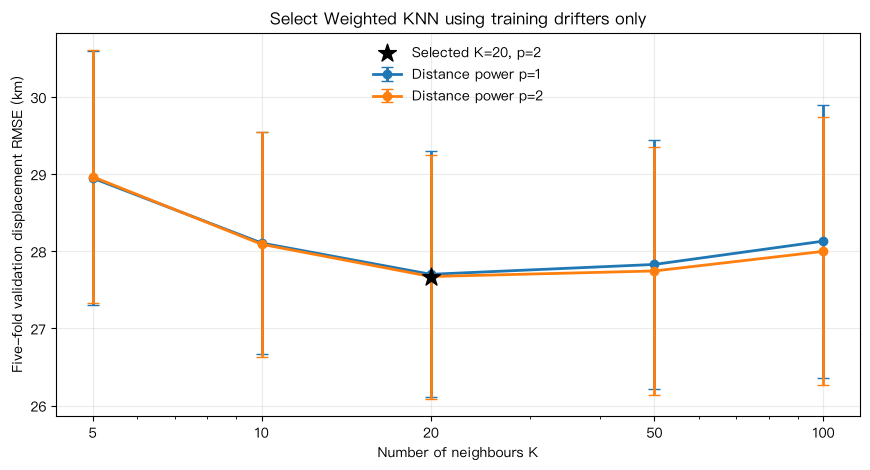

In [8]:
fig, ax = plt.subplots(figsize=(8.8, 4.8))
for power, group in cv_results.groupby('distance_power'):
    ordered = group.sort_values('k')
    ax.errorbar(
        ordered['k'], ordered['mean_cv_rmse_km'],
        yerr=ordered['std_cv_rmse_km'], marker='o', capsize=4,
        linewidth=2, label=f'Distance power p={power:g}',
    )
ax.scatter([best_k], [best_row['mean_cv_rmse_km']], marker='*', s=180, color='black',
           label=f'Selected K={best_k}, p={best_power:g}', zorder=5)
ax.set(
    xlabel='Number of neighbours K', ylabel='Five-fold validation displacement RMSE (km)',
    title='Select Weighted KNN using training drifters only',
)
ax.set_xscale('log')
ax.set_xticks(K_VALUES, labels=[str(k) for k in K_VALUES])
ax.grid(alpha=0.25)
ax.legend(frameon=False)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'knn_cross_validation.png', dpi=200, bbox_inches='tight')
plt.show()

## 8. Build the final neighbour library from all training cases

KNN training consists of storing standardised training inputs and their future targets. The fixed configuration then predicts all 757 test cases.


In [9]:
X_train_standard, X_test_standard, x_mean, x_scale = standardise_from_training(
    X[train_indices], X[test_indices]
)
test_neighbour_indices, test_neighbour_distances = find_nearest_neighbours(
    X_train_standard, X_test_standard, max_k=MAX_K
)
test_prediction_flat, test_effective_neighbours = weighted_knn_predict(
    Y[train_indices], test_neighbour_indices, test_neighbour_distances,
    best_k, best_power,
)
test_predictions = test_prediction_flat.reshape(len(test_indices), HORIZON_HOURS, 2)

test_origins = origins.loc[test_indices].reset_index(drop=True)
nearest_training_rows = train_indices[test_neighbour_indices[:, 0]]
nearest_diagnostics = pd.DataFrame({
    'forecast_case_id': test_origins['forecast_case_id'].to_numpy(),
    'test_drifter_ID': test_origins['ID'].to_numpy(),
    'nearest_training_case_id': origins.loc[nearest_training_rows, 'forecast_case_id'].to_numpy(),
    'nearest_training_drifter_ID': origins.loc[nearest_training_rows, 'ID'].to_numpy(),
    'nearest_distance': test_neighbour_distances[:, 0],
    'effective_neighbours': test_effective_neighbours,
})

assert set(test_origins['ID']).isdisjoint(set(origins.loc[train_indices, 'ID']))
assert nearest_diagnostics['test_drifter_ID'].ne(
    nearest_diagnostics['nearest_training_drifter_ID']
).all()

display(nearest_diagnostics[['nearest_distance', 'effective_neighbours']].describe().round(2))
display(nearest_diagnostics.head())

,nearest_distance,effective_neighbours
count,757.00,757.00
mean,0.31,18.94
std,0.11,1.31
min,0.05,2.43
25%,0.24,18.73
50%,0.29,19.27
75%,0.36,19.56
max,1.03,19.96


,forecast_case_id,test_drifter_ID,nearest_training_case_id,nearest_training_drifter_ID,nearest_distance,effective_neighbours
0,80,39616,4794,300234066411870,0.419510,19.641607
1,81,39616,2207,82464,0.297061,19.402005
2,82,39616,1615,67196,0.365175,19.236915
3,83,39616,4161,300234063943340,0.293284,19.599919
4,84,39616,3615,2885139,0.512718,19.839520


## 9. Convert predictions and calculate held-out error

Predicted displacement trajectories are converted back to geographic coordinates. Explicit checks verify that no test drifter enters the neighbour library.


In [10]:
origin_latitudes = np.repeat(test_origins['origin_latitude'].to_numpy(), HORIZON_HOURS)
origin_longitudes = np.repeat(test_origins['origin_longitude'].to_numpy(), HORIZON_HOURS)
predicted_latitude, predicted_longitude = local_km_to_latlon(
    origin_latitudes, origin_longitudes,
    test_predictions[:, :, 0].reshape(-1),
    test_predictions[:, :, 1].reshape(-1),
)

test_target_mask = targets['forecast_case_id'].isin(test_origins['forecast_case_id'])
test_targets = targets.loc[test_target_mask].sort_values(
    ['forecast_case_id', 'lead_time_hours']
).reset_index(drop=True)

evaluation = pd.DataFrame({
    'forecast_case_id': np.repeat(test_origins['forecast_case_id'].to_numpy(), HORIZON_HOURS),
    'ID': np.repeat(test_origins['ID'].to_numpy(), HORIZON_HOURS),
    'lead_time_hours': np.tile(np.arange(1, HORIZON_HOURS + 1), len(test_origins)),
    'origin_latitude': origin_latitudes,
    'origin_longitude': origin_longitudes,
    'predicted_east_km': test_predictions[:, :, 0].reshape(-1),
    'predicted_north_km': test_predictions[:, :, 1].reshape(-1),
    'pred_latitude': predicted_latitude,
    'pred_longitude': predicted_longitude,
    'true_latitude': test_targets['latitude'].to_numpy(),
    'true_longitude': test_targets['longitude'].to_numpy(),
})
evaluation['separation_error_km'] = haversine_km(
    evaluation['pred_latitude'], evaluation['pred_longitude'],
    evaluation['true_latitude'], evaluation['true_longitude'],
)

checks = pd.Series({
    'Evaluate only 757 test cases': evaluation['forecast_case_id'].nunique() == 757,
    'Every test case has exactly 72 lead times': evaluation.groupby('forecast_case_id').size().eq(72).all(),
    'All errors are finite': np.isfinite(evaluation['separation_error_km']).all(),
    'Test drifters are absent from the neighbour library': set(test_origins['ID']).isdisjoint(set(origins.loc[train_indices, 'ID'])),
    'Calibration cases remain unused': len(calibration_indices) == 769,
}, name='Passed')
display(checks.to_frame())
assert checks.all()

,Passed
Evaluate only 757 test cases,True
Every test case has exactly 72 lead times,True
All errors are finite,True
Test drifters are absent from the neighbour library,True
Calibration cases remain unused,True


## 10. Held-out test error by lead time

Report median, mean, interquartile range and RMSE at every forecast hour.


,lead_time_hours,n,median_error_km,mean_error_km,q25_error_km,q75_error_km,rmse_km
0,1,757,0.48,0.61,0.29,0.80,0.78
5,6,757,3.25,3.82,1.89,4.92,4.69
11,12,757,6.11,7.54,3.63,9.27,9.60
23,24,757,12.03,15.20,6.93,19.53,19.35
47,48,757,27.00,33.54,15.96,43.87,42.42
71,72,757,41.99,52.14,24.35,68.56,65.21


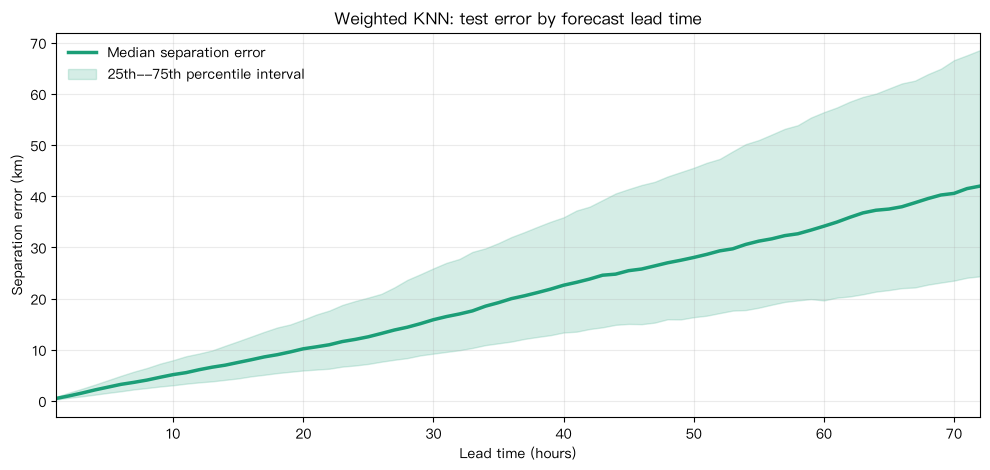

In [11]:
lead_metrics = (
    evaluation.groupby('lead_time_hours')['separation_error_km']
    .agg(
        n='size', median_error_km='median', mean_error_km='mean',
        q25_error_km=lambda x: x.quantile(0.25),
        q75_error_km=lambda x: x.quantile(0.75),
        rmse_km=lambda x: np.sqrt(np.mean(np.square(x))),
    ).reset_index()
)
display(lead_metrics[lead_metrics['lead_time_hours'].isin([1, 6, 12, 24, 48, 72])].round(2))

fig, ax = plt.subplots(figsize=(10, 4.8))
x = lead_metrics['lead_time_hours'].to_numpy()
median = lead_metrics['median_error_km'].to_numpy()
q25 = lead_metrics['q25_error_km'].to_numpy()
q75 = lead_metrics['q75_error_km'].to_numpy()
ax.plot(x, median, color='#1b9e77', linewidth=2.5, label='Median separation error')
ax.fill_between(x, q25, q75, color='#1b9e77', alpha=0.18, label='25th--75th percentile interval')
ax.set(
    xlabel='Lead time (hours)', ylabel='Separation error (km)',
    title='Weighted KNN: test error by forecast lead time',
)
ax.set_xlim(1, 72)
ax.grid(alpha=0.25)
ax.legend(frameon=False)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'knn_error_curve.png', dpi=200, bbox_inches='tight')
plt.show()

## 11. Fair comparison with the five existing models

All six methods use identical test cases and metrics. RMSE skill quantifies improvement relative to each reference model.


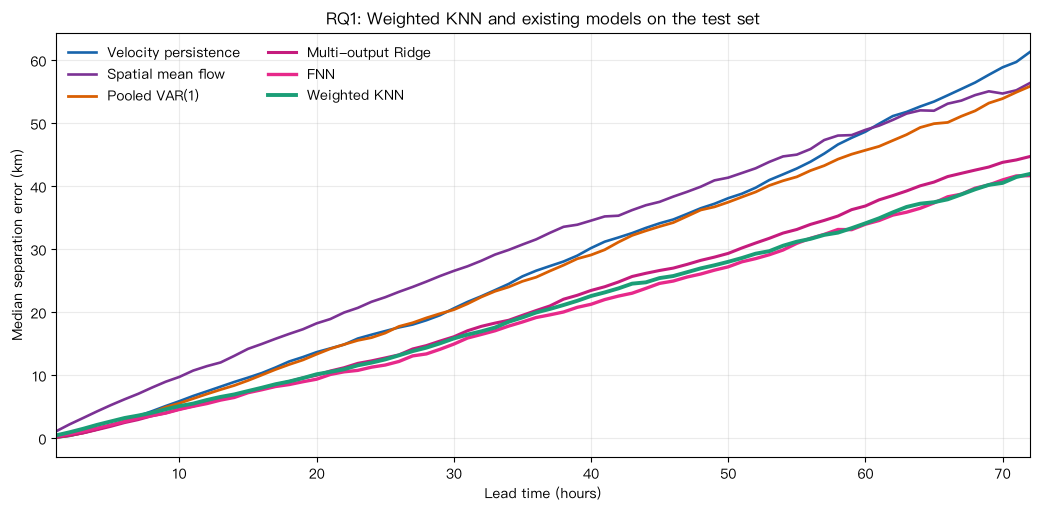

,knn_median_km,fnn_median_km,ridge_median_km,var1_median_km,persistence_median_km,mean_flow_median_km,knn_rmse_km,fnn_rmse_km,ridge_rmse_km,var1_rmse_km,persistence_rmse_km,mean_flow_rmse_km,knn_rmse_minus_fnn_km,skill_vs_fnn_pct,skill_vs_persistence_pct,skill_vs_mean_flow_pct
lead_time_hours,,,,,,,,,,,,,,,,
24,12.03,11.32,12.32,16.00,16.47,21.69,19.35,18.15,18.97,22.49,24.07,29.87,1.19,-6.56,19.63,35.23
48,27.00,26.10,28.27,36.27,36.54,39.96,42.42,40.21,42.59,50.55,55.17,57.27,2.21,-5.51,23.11,25.92
72,41.99,41.72,44.75,55.89,61.35,56.42,65.21,62.15,65.91,77.89,90.10,80.98,3.06,-4.93,27.62,19.47


In [12]:
reference_files = {
    'persistence': 'velocity_persistence_lead_metrics.csv',
    'mean_flow': 'spatial_mean_flow_lead_metrics.csv',
    'ridge': 'ridge_lead_metrics.csv',
    'fnn': 'fnn_lead_metrics.csv',
    'var1': 'var1_lead_metrics.csv',
}
comparison = lead_metrics[['lead_time_hours', 'median_error_km', 'rmse_km']].rename(columns={
    'median_error_km': 'knn_median_km', 'rmse_km': 'knn_rmse_km',
})
for name, filename in reference_files.items():
    frame = pd.read_csv(OUTPUT_DIR / filename)
    comparison = comparison.merge(
        frame[['lead_time_hours', 'median_error_km', 'rmse_km']].rename(columns={
            'median_error_km': f'{name}_median_km', 'rmse_km': f'{name}_rmse_km',
        }), on='lead_time_hours', validate='one_to_one',
    )
    comparison[f'knn_rmse_minus_{name}_km'] = comparison['knn_rmse_km'] - comparison[f'{name}_rmse_km']
    comparison[f'skill_vs_{name}_pct'] = 100 * (1 - comparison['knn_rmse_km'] / comparison[f'{name}_rmse_km'])

fig, ax = plt.subplots(figsize=(10.5, 5.2))
for column, label, color, width in [
    ('persistence_median_km', 'Velocity persistence', '#1764ab', 1.9),
    ('mean_flow_median_km', 'Spatial mean flow', '#7b3294', 1.9),
    ('var1_median_km', 'Pooled VAR(1)', '#d95f02', 2.0),
    ('ridge_median_km', 'Multi-output Ridge', '#c51b7d', 2.2),
    ('fnn_median_km', 'FNN', '#e7298a', 2.4),
    ('knn_median_km', 'Weighted KNN', '#1b9e77', 2.8),
]:
    ax.plot(comparison['lead_time_hours'], comparison[column], linewidth=width, color=color, label=label)
ax.set(
    xlabel='Lead time (hours)', ylabel='Median separation error (km)',
    title='RQ1: Weighted KNN and existing models on the test set',
)
ax.set_xlim(1, 72)
ax.grid(alpha=0.25)
ax.legend(frameon=False, ncol=2)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'rq1_six_model_comparison.png', dpi=200, bbox_inches='tight')
plt.show()

comparison_table = comparison.loc[
    comparison['lead_time_hours'].isin([24, 48, 72]),
    [
        'lead_time_hours', 'knn_median_km', 'fnn_median_km', 'ridge_median_km',
        'var1_median_km', 'persistence_median_km', 'mean_flow_median_km',
        'knn_rmse_km', 'fnn_rmse_km', 'ridge_rmse_km', 'var1_rmse_km',
        'persistence_rmse_km', 'mean_flow_rmse_km',
        'knn_rmse_minus_fnn_km', 'skill_vs_fnn_pct',
        'skill_vs_persistence_pct', 'skill_vs_mean_flow_pct',
    ],
].set_index('lead_time_hours')
display(comparison_table.round(2))

## 12. Case-level integrated trajectory error and final summary

ITE measures error accumulated over the complete trajectory, while endpoint metrics describe selected lead times.


In [13]:
def case_metrics(group):
    ordered = group.sort_values('lead_time_hours')
    errors = ordered['separation_error_km'].to_numpy()
    hours = ordered['lead_time_hours'].to_numpy()
    ite = np.trapezoid(np.r_[0.0, errors], x=np.r_[0, hours])
    return pd.Series({
        'integrated_trajectory_error_km_h': ite,
        'final_72h_error_km': errors[-1],
        'mean_trajectory_error_km': errors.mean(),
    })

test_case_metrics = evaluation.groupby('forecast_case_id', sort=False).apply(
    case_metrics, include_groups=False
).reset_index()

def metric_at(hour, column):
    return float(lead_metrics.loc[lead_metrics['lead_time_hours'].eq(hour), column].iloc[0])

summary = pd.DataFrame({
    'Metric': [
        'Selected K', 'Selected distance power', 'Training cases',
        'Calibration cases (unused)', 'Test cases', 'Median effective neighbours',
        '24h median error (km)', '48h median error (km)', '72h median error (km)',
        '72h RMSE (km)', 'Median ITE (km·h)',
    ],
    'Value': [
        best_k, best_power, len(train_indices), len(calibration_indices), len(test_indices),
        np.median(test_effective_neighbours),
        metric_at(24, 'median_error_km'), metric_at(48, 'median_error_km'),
        metric_at(72, 'median_error_km'), metric_at(72, 'rmse_km'),
        test_case_metrics['integrated_trajectory_error_km_h'].median(),
    ],
})
display(summary.round(4))

,Metric,Value
0,Selected K,20.0000
1,Selected distance power,2.0000
2,Training cases,3591.0000
3,Calibration cases (unused),769.0000
4,Test cases,757.0000
5,Median effective neighbours,19.2715
6,24h median error (km),12.0336
7,48h median error (km),27.0001
8,72h median error (km),41.9875
9,72h RMSE (km),65.2119


## 13. Representative test trajectory and its neighbours

The left panel shows a median-error test example. The right panel displays the training trajectories used in its weighted prediction, making the analogue mechanism inspectable.


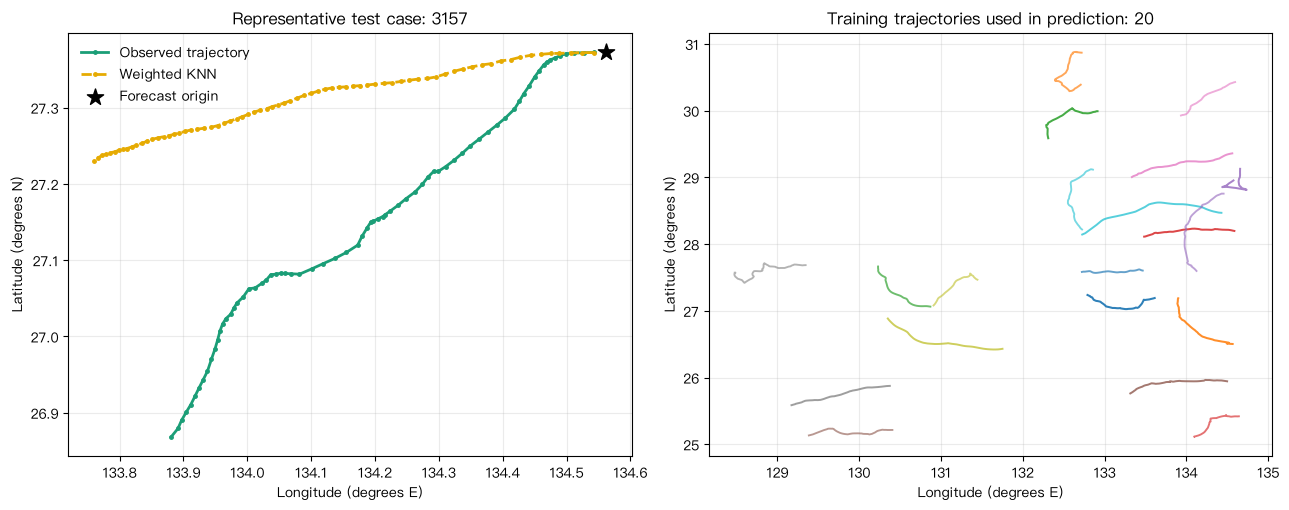

In [14]:
median_final = test_case_metrics['final_72h_error_km'].median()
example_id = test_case_metrics.loc[
    (test_case_metrics['final_72h_error_km'] - median_final).abs().idxmin(),
    'forecast_case_id',
]
example_test_position = int(np.flatnonzero(test_origins['forecast_case_id'].eq(example_id))[0])
example = evaluation[evaluation['forecast_case_id'].eq(example_id)].sort_values('lead_time_hours')

example_neighbour_local = test_neighbour_indices[example_test_position, :best_k]
example_neighbour_rows = train_indices[example_neighbour_local]
example_distances = test_neighbour_distances[example_test_position, :best_k]
example_weights = 1.0 / np.power(example_distances + 1e-8, best_power)
example_weights /= example_weights.sum()

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
axes[0].plot(example['true_longitude'], example['true_latitude'], '-o', markersize=2.5,
             linewidth=2, color='#1b9e77', label='Observed trajectory')
axes[0].plot(example['pred_longitude'], example['pred_latitude'], '--o', markersize=2.5,
             linewidth=2, color='#e6ab02', label='Weighted KNN')
axes[0].scatter(example['origin_longitude'].iloc[0], example['origin_latitude'].iloc[0],
                marker='*', s=150, color='black', label='Forecast origin', zorder=5)
axes[0].set_title(f'Representative test case: {int(example_id)}')
axes[0].set_xlabel('Longitude (degrees E)')
axes[0].set_ylabel('Latitude (degrees N)')
axes[0].grid(alpha=0.25)
axes[0].legend(frameon=False)

# Convert neighbours to their own geographic coordinates to show the historical analogues used by KNN.
for rank, (row_index, weight) in enumerate(zip(example_neighbour_rows, example_weights), start=1):
    neighbour_origin = origins.loc[row_index]
    neighbour_displacement = Y[row_index].reshape(HORIZON_HOURS, 2)
    neighbour_lat, neighbour_lon = local_km_to_latlon(
        np.repeat(neighbour_origin['origin_latitude'], HORIZON_HOURS),
        np.repeat(neighbour_origin['origin_longitude'], HORIZON_HOURS),
        neighbour_displacement[:, 0], neighbour_displacement[:, 1],
    )
    axes[1].plot(
        neighbour_lon, neighbour_lat,
        linewidth=1.2 + 4 * weight,
        alpha=0.18 + 0.75 * weight / example_weights.max(),
        label=f'Neighbour {rank}' if rank <= 5 else None,
    )
axes[1].set_title(f'Training trajectories used in prediction: {best_k}')
axes[1].set_xlabel('Longitude (degrees E)')
axes[1].set_ylabel('Latitude (degrees N)')
axes[1].grid(alpha=0.25)
if best_k <= 5:
    axes[1].legend(frameon=False)

plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'knn_example_trajectory_and_neighbours.png', dpi=200, bbox_inches='tight')
plt.show()

## 14. Save reproducible results

Save grouped cross-validation, neighbour diagnostics, held-out metrics, comparison tables and figures.


In [15]:
cv_folds.to_csv(OUTPUT_DIR / 'knn_cross_validation_folds.csv', index=False)
cv_results.to_csv(OUTPUT_DIR / 'knn_cross_validation_summary.csv', index=False)
nearest_diagnostics.to_csv(OUTPUT_DIR / 'knn_test_neighbour_diagnostics.csv', index=False)
lead_metrics.to_csv(OUTPUT_DIR / 'knn_lead_metrics.csv', index=False)
test_case_metrics.to_csv(OUTPUT_DIR / 'knn_test_case_metrics.csv', index=False)
comparison.to_csv(OUTPUT_DIR / 'rq1_six_model_comparison.csv', index=False)
summary.to_csv(OUTPUT_DIR / 'knn_summary.csv', index=False)
np.savez_compressed(
    OUTPUT_DIR / 'knn_model_parameters.npz',
    k=best_k, distance_power=best_power,
    x_mean=x_mean, x_scale=x_scale,
    training_indices=train_indices,
)

saved_files = sorted(
    [p.name for p in OUTPUT_DIR.glob('knn_*')]
    + [p.name for p in OUTPUT_DIR.glob('rq1_six_model_*')]
)
print('Saved:')
for name in saved_files:
    print(' -', name)

Saved:
 - knn_cross_validation.png
 - knn_cross_validation_folds.csv
 - knn_cross_validation_summary.csv
 - knn_error_curve.png
 - knn_example_trajectory_and_neighbours.png
 - knn_lead_metrics.csv
 - knn_model_parameters.npz
 - knn_summary.csv
 - knn_test_case_metrics.csv
 - knn_test_neighbour_diagnostics.csv
 - rq1_six_model_comparison.csv
 - rq1_six_model_comparison.png
